# Classical Image Segmentation: GrabCut and Watershed

Implementation, parameter tuning, and evaluation of GrabCut and Watershed using the development set, followed by segmentation mask generation on the test set.

In [24]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

In [25]:
# Check that every image has a corresponding ground-truth mask
from pathlib import Path

images = sorted(Path("data/images").glob("*.jpg"))
masks = sorted(Path("data/masks").glob("*.png"))

print(f"Images: {len(images)}")
print(f"Masks: {len(masks)}")

image_ids = {p.stem for p in images}
mask_ids = {p.stem for p in masks}

print(f"Images without masks: {len(image_ids - mask_ids)}")
print(f"Masks without images: {len(mask_ids - image_ids)}")

Images: 1000
Masks: 1000
Images without masks: 0
Masks without images: 0


In [26]:
# Split ECSSD Dataset into 70/30 dev/test split
import random
random.seed(42)
random.shuffle(images)

split_idx = int(0.7 * len(images))
dev_images = images[:split_idx]
test_images = images[split_idx:]

print(f"Dev images: {len(dev_images)}")
print(f"Test images: {len(test_images)}")


Dev images: 700
Test images: 300


In [27]:
import pandas as pd

# Save dev/test splits using image filenames
pd.DataFrame({
    "filename": [p.name for p in dev_images]
}).to_csv("dev_split.csv", index=False)

pd.DataFrame({
    "filename": [p.name for p in test_images]
}).to_csv("test_split.csv", index=False)

print("Dev and test splits saved successfully!")

Dev and test splits saved successfully!


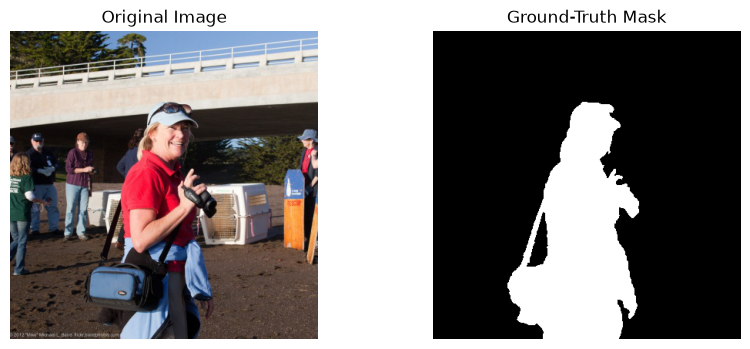

In [28]:
# Visualize a sample image and its ground-truth mask

image_path = dev_images[0]
mask_path = Path("data/masks") / f"{image_path.stem}.png"

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground-Truth Mask")

for ax in axes:
    ax.axis("off")

plt.show()

### GrabCut Implementation

In [ ]:
# GrabCut Segmentation Function
def run_grabcut(image, padding=0.1, iterations=5):
    height, width = image.shape[:2]

    # Calculate rectangle padding
    px = int(padding * width)
    py = int(padding * height)

    rect = (px, py, width - 2*px, height - 2*py)

    # Initialize GrabCut
    mask = np.zeros((height, width), dtype=np.uint8)
    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)

    # Run GrabCut
    cv2.grabCut(
        image, mask, rect,
        bg_model, fg_model,
        iterations, cv2.GC_INIT_WITH_RECT
    )

    # Convert to binary mask
    return np.where(
        (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

In [33]:
# Calculate IoU between predicted and ground-truth masks

def calculate_iou(predicted, ground_truth):
    pred = predicted > 127
    gt = ground_truth > 127

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    return intersection / union if union > 0 else 1.0

In [ ]:
# GrabCut Parameter Tuning: Broad Search

import itertools
import pandas as pd

def evaluate_configurations(configurations):
    results = []

    for padding, iterations in configurations:
        scores = []

        for image_path in dev_images:
            image = cv2.imread(str(image_path))
            mask_path = Path("data/masks") / f"{image_path.stem}.png"
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

            if image is None or gt_mask is None:
                raise ValueError(f"Could not load {image_path}")

            predicted = run_grabcut(image, padding, iterations)
            scores.append(calculate_iou(predicted, gt_mask))

        mean_iou = np.mean(scores)

        results.append({
            "padding": padding,
            "iterations": iterations,
            "mean_iou": mean_iou
        })

        print(f"Padding: {padding:.0%}, "
              f"Iterations: {iterations}, "
              f"Mean IoU: {mean_iou:.4f}", flush=True)

    return pd.DataFrame(results)


# Broad search
broad_paddings = [0.01, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25]
broad_iterations = [1, 3, 5, 10]

broad_configs = list(itertools.product(
    broad_paddings, broad_iterations
))

print("Starting broad search...")
broad_results = evaluate_configurations(broad_configs)

best_broad = broad_results.loc[broad_results["mean_iou"].idxmax()]

print("\nBest Broad Search Configuration:")
print(best_broad)

Starting broad search...
Padding: 1%, Iterations: 1, Mean IoU: 0.5366
Padding: 1%, Iterations: 3, Mean IoU: 0.5935
Padding: 1%, Iterations: 5, Mean IoU: 0.6015
Padding: 1%, Iterations: 10, Mean IoU: 0.6047
Padding: 3%, Iterations: 1, Mean IoU: 0.5604
Padding: 3%, Iterations: 3, Mean IoU: 0.6052
Padding: 3%, Iterations: 5, Mean IoU: 0.6088
Padding: 3%, Iterations: 10, Mean IoU: 0.6120
Padding: 5%, Iterations: 1, Mean IoU: 0.5683
Padding: 5%, Iterations: 3, Mean IoU: 0.6090
Padding: 5%, Iterations: 5, Mean IoU: 0.6149
Padding: 5%, Iterations: 10, Mean IoU: 0.6185
Padding: 8%, Iterations: 1, Mean IoU: 0.5715
Padding: 8%, Iterations: 3, Mean IoU: 0.6082
Padding: 8%, Iterations: 5, Mean IoU: 0.6133
Padding: 8%, Iterations: 10, Mean IoU: 0.6144
Padding: 10%, Iterations: 1, Mean IoU: 0.5766
Padding: 10%, Iterations: 3, Mean IoU: 0.6095
Padding: 10%, Iterations: 5, Mean IoU: 0.6127
Padding: 10%, Iterations: 10, Mean IoU: 0.6147
Padding: 15%, Iterations: 1, Mean IoU: 0.5493
Padding: 15%, Iterat

In [36]:
# GrabCut Parameter Tuning: Fine Search

best_padding = best_broad["padding"]

fine_paddings = np.round(
    np.arange(
        max(0.01, best_padding - 0.03),
        min(0.45, best_padding + 0.03) + 0.001,
        0.01
    ), 3
)

fine_iterations = [3, 5, 10, 15]

fine_configs = [
    (float(p), i)
    for p, i in itertools.product(fine_paddings, fine_iterations)
    if not any(
        abs(p - bp) < 1e-9 and i == bi
        for bp, bi in broad_configs
    )
]

print("Starting fine search...")
fine_results = evaluate_configurations(fine_configs)


# Combine results and select best configuration
all_results = pd.concat(
    [broad_results, fine_results],
    ignore_index=True
)

all_results = all_results.sort_values(
    "mean_iou", ascending=False
)

best = all_results.iloc[0]

print("\n===== BEST GRABCUT CONFIGURATION =====")
print(f"Padding: {best['padding']:.1%}")
print(f"Iterations: {int(best['iterations'])}")
print(f"Mean Dev IoU: {best['mean_iou']:.4f}")

# Save results
all_results.to_csv("grabcut_tuning_results.csv", index=False)

Starting fine search...
Padding: 2%, Iterations: 3, Mean IoU: 0.6009
Padding: 2%, Iterations: 5, Mean IoU: 0.6099
Padding: 2%, Iterations: 10, Mean IoU: 0.6113
Padding: 2%, Iterations: 15, Mean IoU: 0.6099
Padding: 3%, Iterations: 15, Mean IoU: 0.6159
Padding: 4%, Iterations: 3, Mean IoU: 0.6086
Padding: 4%, Iterations: 5, Mean IoU: 0.6208
Padding: 4%, Iterations: 10, Mean IoU: 0.6173
Padding: 4%, Iterations: 15, Mean IoU: 0.6209
Padding: 5%, Iterations: 15, Mean IoU: 0.6130
Padding: 6%, Iterations: 3, Mean IoU: 0.6103
Padding: 6%, Iterations: 5, Mean IoU: 0.6137
Padding: 6%, Iterations: 10, Mean IoU: 0.6151
Padding: 6%, Iterations: 15, Mean IoU: 0.6200
Padding: 7%, Iterations: 3, Mean IoU: 0.6116
Padding: 7%, Iterations: 5, Mean IoU: 0.6148
Padding: 7%, Iterations: 10, Mean IoU: 0.6156
Padding: 7%, Iterations: 15, Mean IoU: 0.6135
Padding: 8%, Iterations: 15, Mean IoU: 0.6136

===== BEST GRABCUT CONFIGURATION =====
Padding: 4.0%
Iterations: 15
Mean Dev IoU: 0.6209


### Implement Watershed

In [53]:
# Watershed Segmentation Function

def run_watershed(image, blur_size=7, foreground_size=0.10, border_size=0.05):
    height, width = image.shape[:2]

    # Smooth the image
    blurred = cv2.GaussianBlur(image, (blur_size, blur_size), 0)

    # Initialize markers
    markers = np.zeros((height, width), dtype=np.int32)

    # Background markers near image borders
    border = max(1, int(border_size * min(height, width)))

    markers[:border, :] = 1
    markers[-border:, :] = 1
    markers[:, :border] = 1
    markers[:, -border:] = 1

    # Foreground marker in the central region
    center_h = max(1, int(foreground_size * height))
    center_w = max(1, int(foreground_size * width))

    cy, cx = height // 2, width // 2

    markers[
        cy - center_h // 2:cy + (center_h + 1) // 2,
        cx - center_w // 2:cx + (center_w + 1) // 2
    ] = 2

    # Apply Watershed
    markers = cv2.watershed(blurred, markers)

    # Convert foreground region to binary mask
    predicted_mask = np.where(
        markers == 2, 255, 0
    ).astype(np.uint8)

    return predicted_mask

In [54]:
# Watershed Broad Parameter Search

def evaluate_watershed_configurations(configurations):
    results = []

    for blur_size, foreground_size, border_size in configurations:
        scores = []

        for image_path in dev_images:
            image = cv2.imread(str(image_path))

            gt_mask = cv2.imread(
                str(Path("data/masks") / f"{image_path.stem}.png"),
                cv2.IMREAD_GRAYSCALE
            )

            if image is None or gt_mask is None:
                raise ValueError(f"Could not load {image_path}")

            predicted = run_watershed(
                image,
                blur_size=blur_size,
                foreground_size=foreground_size,
                border_size=border_size
            )

            scores.append(calculate_iou(predicted, gt_mask))

        mean_iou = np.mean(scores)

        results.append({
            "blur_size": blur_size,
            "foreground_size": foreground_size,
            "border_size": border_size,
            "mean_iou": mean_iou
        })

        print(
            f"Blur: {blur_size}, "
            f"Foreground: {foreground_size:.0%}, "
            f"Border: {border_size:.0%}, "
            f"Mean IoU: {mean_iou:.4f}",
            flush=True
        )

    return pd.DataFrame(results)


broad_blurs = [3, 5, 7, 9]
broad_foregrounds = [0.05, 0.10, 0.15, 0.20]
broad_borders = [0.02, 0.05, 0.10]

watershed_broad_configs = list(
    itertools.product(
        broad_blurs,
        broad_foregrounds,
        broad_borders
    )
)

print("Starting Watershed broad search...")

watershed_broad_results = evaluate_watershed_configurations(
    watershed_broad_configs
)

best_watershed_broad = watershed_broad_results.loc[
    watershed_broad_results["mean_iou"].idxmax()
]

print("\nBest Watershed Broad Search Configuration:")
print(best_watershed_broad)

watershed_broad_results.to_csv(
    "watershed_broad_results.csv",
    index=False
)

Starting Watershed broad search...
Blur: 3, Foreground: 5%, Border: 2%, Mean IoU: 0.4019
Blur: 3, Foreground: 5%, Border: 5%, Mean IoU: 0.3877
Blur: 3, Foreground: 5%, Border: 10%, Mean IoU: 0.3646
Blur: 3, Foreground: 10%, Border: 2%, Mean IoU: 0.4474
Blur: 3, Foreground: 10%, Border: 5%, Mean IoU: 0.4363
Blur: 3, Foreground: 10%, Border: 10%, Mean IoU: 0.4157
Blur: 3, Foreground: 15%, Border: 2%, Mean IoU: 0.4713
Blur: 3, Foreground: 15%, Border: 5%, Mean IoU: 0.4599
Blur: 3, Foreground: 15%, Border: 10%, Mean IoU: 0.4403
Blur: 3, Foreground: 20%, Border: 2%, Mean IoU: 0.4811
Blur: 3, Foreground: 20%, Border: 5%, Mean IoU: 0.4746
Blur: 3, Foreground: 20%, Border: 10%, Mean IoU: 0.4602
Blur: 5, Foreground: 5%, Border: 2%, Mean IoU: 0.3987
Blur: 5, Foreground: 5%, Border: 5%, Mean IoU: 0.3875
Blur: 5, Foreground: 5%, Border: 10%, Mean IoU: 0.3625
Blur: 5, Foreground: 10%, Border: 2%, Mean IoU: 0.4529
Blur: 5, Foreground: 10%, Border: 5%, Mean IoU: 0.4415
Blur: 5, Foreground: 10%, Borde

In [55]:
# Watershed Fine Parameter Search

best_blur = int(best_watershed_broad["blur_size"])
best_foreground = float(best_watershed_broad["foreground_size"])
best_border = float(best_watershed_broad["border_size"])

fine_blurs = [
    b for b in [best_blur - 2, best_blur, best_blur + 2]
    if b >= 3
]

fine_foregrounds = np.round(
    np.arange(
        max(0.02, best_foreground - 0.04),
        min(0.30, best_foreground + 0.04) + 0.001,
        0.02
    ),
    3
)

fine_borders = np.round(
    np.arange(
        max(0.01, best_border - 0.02),
        min(0.15, best_border + 0.02) + 0.001,
        0.01
    ),
    3
)

watershed_fine_configs = [
    (int(b), float(f), float(r))
    for b, f, r in itertools.product(
        fine_blurs, fine_foregrounds, fine_borders
    )
    if not any(
        b == bb and abs(f - bf) < 1e-9 and abs(r - br) < 1e-9
        for bb, bf, br in watershed_broad_configs
    )
]

print("Starting Watershed fine search...")

watershed_fine_results = evaluate_watershed_configurations(
    watershed_fine_configs
)

watershed_all_results = pd.concat(
    [watershed_broad_results, watershed_fine_results],
    ignore_index=True
).sort_values("mean_iou", ascending=False)

best_watershed = watershed_all_results.iloc[0]

print("\n===== BEST WATERSHED CONFIGURATION =====")
print(f"Blur size: {int(best_watershed['blur_size'])}")
print(f"Foreground size: {best_watershed['foreground_size']:.1%}")
print(f"Border size: {best_watershed['border_size']:.1%}")
print(f"Mean Dev IoU: {best_watershed['mean_iou']:.4f}")

watershed_all_results.to_csv(
    "watershed_tuning_results.csv",
    index=False
)

Starting Watershed fine search...
Blur: 7, Foreground: 16%, Border: 1%, Mean IoU: 0.4746
Blur: 7, Foreground: 16%, Border: 2%, Mean IoU: 0.4746
Blur: 7, Foreground: 16%, Border: 3%, Mean IoU: 0.4746
Blur: 7, Foreground: 16%, Border: 4%, Mean IoU: 0.4722
Blur: 7, Foreground: 18%, Border: 1%, Mean IoU: 0.4765
Blur: 7, Foreground: 18%, Border: 2%, Mean IoU: 0.4780
Blur: 7, Foreground: 18%, Border: 3%, Mean IoU: 0.4775
Blur: 7, Foreground: 18%, Border: 4%, Mean IoU: 0.4762
Blur: 7, Foreground: 20%, Border: 1%, Mean IoU: 0.4809
Blur: 7, Foreground: 20%, Border: 3%, Mean IoU: 0.4814
Blur: 7, Foreground: 20%, Border: 4%, Mean IoU: 0.4805
Blur: 7, Foreground: 22%, Border: 1%, Mean IoU: 0.4810
Blur: 7, Foreground: 22%, Border: 2%, Mean IoU: 0.4815
Blur: 7, Foreground: 22%, Border: 3%, Mean IoU: 0.4822
Blur: 7, Foreground: 22%, Border: 4%, Mean IoU: 0.4821
Blur: 7, Foreground: 24%, Border: 1%, Mean IoU: 0.4823
Blur: 7, Foreground: 24%, Border: 2%, Mean IoU: 0.4823
Blur: 7, Foreground: 24%, Borde

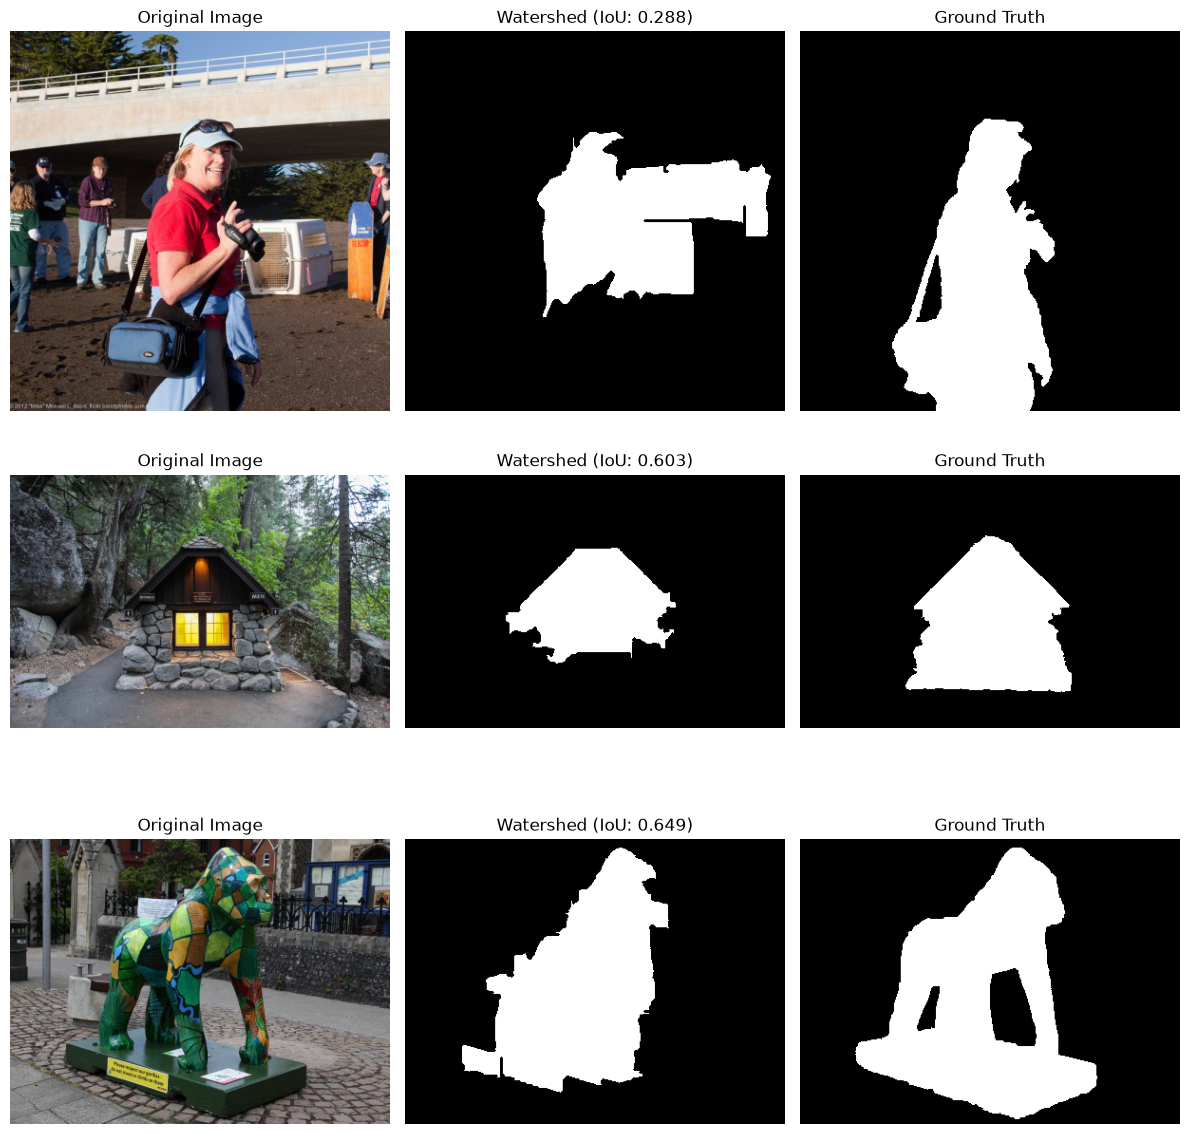

In [56]:
# Visualize Tuned Watershed Predictions Against Ground Truth

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, image_path in enumerate(dev_images[:3]):
    image = cv2.imread(str(image_path))

    gt_mask = cv2.imread(
        str(Path("data/masks") / f"{image_path.stem}.png"),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None or gt_mask is None:
        raise ValueError(f"Could not load {image_path}")

    # Apply Watershed using the best tuned parameters
    predicted = run_watershed(
        image,
        blur_size=11,
        foreground_size=0.20,
        border_size=0.02
    )

    axes[row, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(predicted, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(
        f"Watershed (IoU: {calculate_iou(predicted, gt_mask):.3f})"
    )

    axes[row, 2].imshow(gt_mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title("Ground Truth")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Generate prediction masks for GrabCut and Watershed

In [57]:
# Generate GrabCut Predictions on Test Set

grabcut_results = pd.read_csv("grabcut_tuning_results.csv")
best_grabcut = grabcut_results.loc[grabcut_results["mean_iou"].idxmax()]

best_padding = float(best_grabcut["padding"])
best_iterations = int(best_grabcut["iterations"])

grabcut_output = Path("outputs/grabcut")
grabcut_output.mkdir(parents=True, exist_ok=True)

for i, image_path in enumerate(test_images, start=1):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load {image_path}")

    predicted = run_grabcut(
        image,
        padding=best_padding,
        iterations=best_iterations
    )

    output_path = grabcut_output / f"{image_path.stem}.png"

    if not cv2.imwrite(str(output_path), predicted):
        raise IOError(f"Could not save {output_path}")

    if i % 25 == 0 or i == len(test_images):
        print(f"GrabCut: {i}/{len(test_images)} completed", flush=True)

print("GrabCut test predictions saved.")

GrabCut: 25/300 completed
GrabCut: 50/300 completed
GrabCut: 75/300 completed
GrabCut: 100/300 completed
GrabCut: 125/300 completed
GrabCut: 150/300 completed
GrabCut: 175/300 completed
GrabCut: 200/300 completed
GrabCut: 225/300 completed
GrabCut: 250/300 completed
GrabCut: 275/300 completed
GrabCut: 300/300 completed
GrabCut test predictions saved.


In [58]:
# Generate Watershed Predictions on Test Set

watershed_results = pd.read_csv("watershed_tuning_results.csv")
best_watershed = watershed_results.loc[
    watershed_results["mean_iou"].idxmax()
]

best_blur = int(best_watershed["blur_size"])
best_foreground = float(best_watershed["foreground_size"])
best_border = float(best_watershed["border_size"])

watershed_output = Path("outputs/watershed")
watershed_output.mkdir(parents=True, exist_ok=True)

for i, image_path in enumerate(test_images, start=1):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load {image_path}")

    predicted = run_watershed(
        image,
        blur_size=best_blur,
        foreground_size=best_foreground,
        border_size=best_border
    )

    output_path = watershed_output / f"{image_path.stem}.png"

    if not cv2.imwrite(str(output_path), predicted):
        raise IOError(f"Could not save {output_path}")

    if i % 25 == 0 or i == len(test_images):
        print(f"Watershed: {i}/{len(test_images)} completed", flush=True)

print("Watershed test predictions saved.")

Watershed: 25/300 completed
Watershed: 50/300 completed
Watershed: 75/300 completed
Watershed: 100/300 completed
Watershed: 125/300 completed
Watershed: 150/300 completed
Watershed: 175/300 completed
Watershed: 200/300 completed
Watershed: 225/300 completed
Watershed: 250/300 completed
Watershed: 275/300 completed
Watershed: 300/300 completed
Watershed test predictions saved.


### Evaluate GrabCut and Watershed on the Test Set

In [59]:
# Calculate Test IoU for GrabCut and Watershed

results = []

for image_path in test_images:
    filename = f"{image_path.stem}.png"

    # Load ground-truth mask
    gt_mask = cv2.imread(
        str(Path("data/masks") / filename),
        cv2.IMREAD_GRAYSCALE
    )

    # Load predicted masks
    grabcut_mask = cv2.imread(
        str(Path("outputs/grabcut") / filename),
        cv2.IMREAD_GRAYSCALE
    )

    watershed_mask = cv2.imread(
        str(Path("outputs/watershed") / filename),
        cv2.IMREAD_GRAYSCALE
    )

    if gt_mask is None or grabcut_mask is None or watershed_mask is None:
        raise ValueError(f"Missing mask for {filename}")

    if gt_mask.shape != grabcut_mask.shape or gt_mask.shape != watershed_mask.shape:
        raise ValueError(f"Mask dimensions do not match for {filename}")

    # Calculate IoU
    grabcut_iou = calculate_iou(grabcut_mask, gt_mask)
    watershed_iou = calculate_iou(watershed_mask, gt_mask)

    results.append({
        "image": filename,
        "grabcut_iou": grabcut_iou,
        "watershed_iou": watershed_iou
    })

# Save per-image results
test_results = pd.DataFrame(results)
test_results.to_csv("test_iou_results.csv", index=False)

# Calculate mean IoU
print("===== FINAL TEST RESULTS =====")
print(f"Test images evaluated: {len(test_results)}")
print(f"GrabCut Mean Test IoU: {test_results['grabcut_iou'].mean():.4f}")
print(f"Watershed Mean Test IoU: {test_results['watershed_iou'].mean():.4f}")

===== FINAL TEST RESULTS =====
Test images evaluated: 300
GrabCut Mean Test IoU: 0.6168
Watershed Mean Test IoU: 0.4583
